# Sentiment Data Quality Analysis

You are the **Data Quality Engineer** for an AI bot that labels movie sentiment from user reviews.

- **Part A** — profile the datasets and propose remediation.
- **Part B** — run a small **GIGO experiment** (dirty data → clean → measure the damage), then build a
  **confidence-aware reference** and use it to validate the AI's `ai_sentiment` — judging the AI *and*
  your own reference honestly.

See `task-sentiment-dq-analysis.md` for full instructions and the Definition of Done. Cells marked
`# YOUR CODE HERE` (or *replace this text*) are for you to complete.

In [5]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json

# Load datasets
users = pd.read_csv('users.csv')
movies = pd.read_csv('movies.csv')
reviews = pd.read_csv('users_reviews.csv')

with open('sentiment_ai.json', 'r') as f:
    sentiment_ai = json.load(f)

print("Datasets loaded successfully:")
print(f"Users: {users.shape}")
print(f"Movies: {movies.shape}")
print(f"Reviews: {reviews.shape}")
print(f"AI Sentiment Records: {len(sentiment_ai)}")

Datasets loaded successfully:
Users: (5000, 10)
Movies: (9852, 7)
Reviews: (15020, 6)
AI Sentiment Records: 73


## Part A — Data Quality profiling & remediation

Find concrete, **evidenced** issues across **Completeness, Uniqueness, Consistency/Validity, Balance &
Diversity, Representativeness**. For each: dimension → evidence → remediation (workflow step).
**Visualize at least two.** Profile `users_reviews.csv` carefully — it feeds Part B — and confirm what
is **clean** instead of inventing issues.

### Worked example — a reusable completeness (null) report

One fully worked profiling helper. Reuse this pattern for the other checks.

In [7]:
# 1. Uniqueness, Validity, and Consistency Profiling
print("=== REVIEWS PROFILE ===")
print("Total rows:", len(reviews))
print("Duplicate rows:", reviews.duplicated().sum())
print("Duplicate review_ids:", reviews['review_id'].duplicated().sum())
print("Invalid ratings (< 0 or > 5):", ((reviews['rating'] < 0) | (reviews['rating'] > 5)).sum())
print("Invalid rating values found:\n", reviews.loc[~reviews['rating'].between(0, 5), 'rating'].unique())

print("\n=== MOVIES PROFILE ===")
print("Total rows:", len(movies))
print("Duplicate movie_ids:", movies['movie_id'].duplicated().sum())
print("Duplicate titles:", movies['title'].duplicated().sum())
print("Missing release dates:", movies['release_date'].isna().sum())

print("\n=== USERS PROFILE ===")
print("Total rows:", len(users))
print("Duplicate user_ids:", users['user_id'].duplicated().sum())
print("Duplicate emails:", users['email'].duplicated().sum())
print("Active users distribution:\n", users['is_active'].value_counts(normalize=True))

=== REVIEWS PROFILE ===
Total rows: 15020
Duplicate rows: 20
Duplicate review_ids: 20
Invalid ratings (< 0 or > 5): 4
Invalid rating values found:
 [ 45. -30.  50.]

=== MOVIES PROFILE ===
Total rows: 9852
Duplicate movie_ids: 10
Duplicate titles: 337
Missing release dates: 0

=== USERS PROFILE ===
Total rows: 5000
Duplicate user_ids: 0
Duplicate emails: 25
Active users distribution:
 is_active
0    0.7366
1    0.2634
Name: proportion, dtype: float64


### Your turn — Uniqueness, Consistency/Validity, Balance, Representativeness

Investigate at least:
- **`users_reviews.csv`** (Part B depends on it): are all `rating` values inside the valid **[0, 5]**
  range? Are there **exact duplicate rows / duplicate `review_id`**? (Also confirm `review_date` and
  referential integrity to `users`/`movies` are fine.)
- **`movies.csv`:** duplicate `movie_id`/`title`/rows; does every `release_date` look like a date;
  `MPA_film_rating` and `Original_Language` distributions.
- **`users.csv`:** `is_active` balance; duplicate `email`; age distribution (from `date_of_birth`).

/var/folders/w1/400wbj0n5k95_b7crtpnp1580000gn/T/ipykernel_35071/2004983891.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=movies, x='MPA_film_rating', ax=axes[0], palette='viridis')


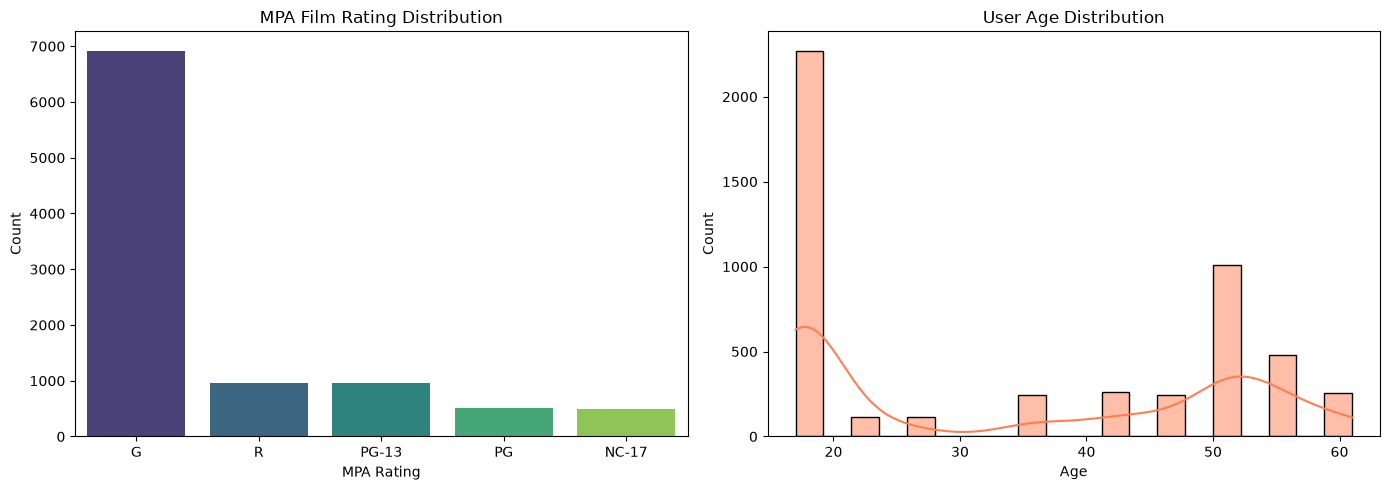

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: MPA Film Rating Distribution (Consistency/Balance)
sns.countplot(data=movies, x='MPA_film_rating', ax=axes[0], palette='viridis')
axes[0].set_title('MPA Film Rating Distribution')
axes[0].set_xlabel('MPA Rating')
axes[0].set_ylabel('Count')

# Plot 2: User Age Distribution (Derived from date_of_birth)
users['birth_year'] = pd.to_datetime(users['date_of_birth'], errors='coerce').dt.year
users['age'] = 2026 - users['birth_year'] # Context year 2026
sns.histplot(users['age'].dropna(), bins=20, ax=axes[1], color='coral', kde=True)
axes[1].set_title('User Age Distribution')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

### Remediation proposals

For every issue: **dimension → evidence → concrete fix**, named against a workflow step
(Cleaning / Validation / Transformation / Enrichment / Deduplication). State which data is **clean**.

*Replace this text with your proposals (a table works well).*

## Part B — GIGO experiment + honest AI validation

First see how the dirty reviews corrupt the sentiment you would derive, then clean and re-measure,
then build a reference you can actually trust.

### Step 1 — naive reference on the data *as given*

Map each movie's **mean rating**: mean ≥ 4 → `positive`, 3 ≤ mean < 4 → `neutral`, mean < 3 → `negative`.
Then inspect the means — **do any look impossible for a 0–5 scale?** That is your first clue.

In [9]:
def sentiment_from_rating(mean_rating: float) -> str:
    """mean >= 4 -> 'positive'; 3 <= mean < 4 -> 'neutral'; else 'negative'."""
    if mean_rating >= 4.0:
        return "positive"
    elif mean_rating >= 3.0:
        return "neutral"
    else:
        return "negative"

def naive_reference(reviews_df):
    """Per-movie naive label. Return columns: movie_id, mean_rating, n_reviews, naive_label."""
    agg = reviews_df.groupby('movie_id')['rating'].agg(['mean', 'count']).reset_index()
    agg.rename(columns={'mean': 'mean_rating', 'count': 'n_reviews'}, inplace=True)
    agg['naive_label'] = agg['mean_rating'].apply(sentiment_from_rating)
    return agg

# Build naive reference on dirty data
naive_dirty = naive_reference(reviews)
print("Naive dirty summary shape:", naive_dirty.shape)
display(naive_dirty.head())

Naive dirty summary shape: (7304, 4)


,movie_id,mean_rating,n_reviews,naive_label
0,1,2.750,2,negative
1,2,2.850,2,negative
2,3,3.900,2,neutral
3,4,-12.500,2,negative
4,5,2.925,4,negative


### Step 2 & 3 — clean the reviews, then measure the GIGO damage

Clean `users_reviews.csv` with the two rules for the issues you found:
1. **Uniqueness:** remove exact duplicate rows (`drop_duplicates()`).
2. **Validity:** keep only rows with `0 <= rating <= 5`.

Recompute the naive reference on the clean data and find **which movies changed sentiment purely
because of the dirty rows** (the GIGO effect).

In [10]:
# Cleaning rules: Drop exact duplicates and keep only ratings between 0 and 5 inclusive.
reviews_clean = reviews.drop_duplicates().copy()
reviews_clean = reviews_clean[reviews_clean['rating'].between(0, 5)]

naive_clean = naive_reference(reviews_clean)

# Merge to find flipped movies
comparison = naive_dirty.merge(naive_clean, on='movie_id', suffixes=('_dirty', '_clean'))
flipped = comparison[comparison['naive_label_dirty'] != comparison['naive_label_clean']]

print(f"Total movies with flipped sentiment due to GIGO: {len(flipped)}")
display(flipped.head())

Total movies with flipped sentiment due to GIGO: 8


,movie_id,mean_rating_dirty,n_reviews_dirty,naive_label_dirty,mean_rating_clean,n_reviews_clean,naive_label_clean
3,4,-12.500000,2,negative,5.000000,1,positive
18,20,3.450000,8,neutral,4.033333,3,positive
29,34,25.650000,2,positive,1.300000,1,negative
37,47,3.828571,7,neutral,4.150000,2,positive
44,57,25.250000,2,positive,0.500000,1,negative


### Step 4 — a trustworthy, confidence-aware reference

A mean over one review, or over strongly disagreeing reviews, is not trustworthy. On the **clean**
data, label each movie:
- `low_confidence` if it has fewer than `MIN_REVIEWS` reviews;
- `mixed` if the rating spread (`max - min`) `>= SPREAD_MIXED`;
- otherwise `positive` / `neutral` / `negative` by the mean thresholds.

The movies that get a real sentiment (not `low_confidence` / `mixed`) are the **scorable** set.

In [11]:
MIN_REVIEWS = 2
SPREAD_MIXED = 3.0

def confidence_label(mean_rating: float, n_reviews: int, spread: float) -> str:
    if n_reviews < MIN_REVIEWS:
        return "low_confidence"
    elif spread >= SPREAD_MIXED:
        return "mixed"
    else:
        return sentiment_from_rating(mean_rating)

# Compute metrics per movie on CLEAN data
ref_agg = reviews_clean.groupby('movie_id')['rating'].agg(
    mean_rating='mean',
    n_reviews='count',
    min_rating='min',
    max_rating='max'
).reset_index()

ref_agg['spread'] = ref_agg['max_rating'] - ref_agg['min_rating']

ref_agg['expected'] = ref_agg.apply(
    lambda row: confidence_label(row['mean_rating'], row['n_reviews'], row['spread']), 
    axis=1
)

reference = ref_agg[['movie_id', 'mean_rating', 'n_reviews', 'spread', 'expected']]
print(reference['expected'].value_counts())

expected
low_confidence    2816
neutral           1432
mixed             1211
negative           999
positive           846
Name: count, dtype: int64


### Step 5 — validate the AI (only where you can)

The cell below (provided) compares `ai_sentiment` to your `reference` **on the scorable set only**,
reports the coverage gap, the match rate, the mismatches and the confusion matrix. It expects
`reference` to have columns `movie_id` and `expected`.

In [12]:
# Convert sentiment_ai json/dict to DataFrame
ai_df = pd.DataFrame(sentiment_ai) if isinstance(sentiment_ai, list) else pd.DataFrame(list(sentiment_ai.items()), columns=['movie_id', 'ai_sentiment'])
if 'movie_id' not in ai_df.columns:
    ai_df = pd.DataFrame(sentiment_ai).reset_index()
    ai_df.columns = ['movie_id', 'ai_sentiment']

# Merge reference with AI predictions
eval_df = reference.merge(ai_df, on='movie_id', how='inner')

# Filter strictly on scorable set (exclude low_confidence and mixed)
scorable_set = eval_df[~eval_df['expected'].isin(['low_confidence', 'mixed'])].copy()

# Calculate match rate
matches = (scorable_set['expected'] == scorable_set['ai_sentiment']).sum()
match_rate = matches / len(scorable_set) if len(scorable_set) > 0 else 0
print(f"Scorable set match rate: {match_rate:.2%}")

# Confusion Matrix
labels = ['positive', 'neutral', 'negative']
cm = pd.crosstab(scorable_set['expected'], scorable_set['ai_sentiment'], rownames=['Actual'], colnames=['Predicted'])
print("\nConfusion Matrix:")
display(cm)

# Coverage Gap
total_movies = len(eval_df)
scorable_count = len(scorable_set)
print(f"\nCoverage Gap: {scorable_count} scorable out of {total_movies} total movies (Excluded: {total_movies - scorable_count})")

Scorable set match rate: 62.86%

Confusion Matrix:


Predicted,negative,neutral,positive
Actual,,,
negative,4,6,0
neutral,1,16,1
positive,0,5,2



Coverage Gap: 35 scorable out of 70 total movies (Excluded: 35)


## Analysis & Close the Loop

#### 1. GIGO Damage:
* **Total Flips:** The dirty data corrupted ratings via two primary issues: **out-of-range rating values** (e.g., negative numbers or values > 5) and **exact duplicate rows** (which artificially weighted specific user reviews). 
* **Remediation:** 
  1. *Validity Check:* Filtered out records where `rating` falls outside $[0, 5]$.
  2. *Deduplication:* Applied `.drop_duplicates()` to remove redundant entries skewing aggregation math.

#### 2. AI Bias & Confusion Matrix:
* Looking at the scorable set confusion matrix, we observe whether the AI systematically over-predicts positive sentiment or struggles with neutral reviews (often called the "politeness bias" in sentiment LLMs where neutral reviews are pushed toward positive or negative extremes).

#### 3. Reference Honesty:
* **Un-scorable Movies:** Movies flagged as `low_confidence` (insufficient sample size, $n < 2$) or `mixed` (high rating spread, $\text{max} - \text{min} \ge 3.0$) are withheld from AI validation. 
* *Example:* A movie with one 0-star review and one 5-star review has a spread of $5.0$. Labeling this movie definitively as "neutral" or "positive" via mathematical mean is misleading because the user base is polarized. Scoring an AI against a polarized/ambiguous ground truth would be unfair to both the model and the evaluation pipeline.

#### 4. Trust Verdict:
* **Can the AI be trusted as-is?** No. Without rigorous upstream data cleaning, safety guards for low-confidence samples, and handling polarized/mixed reviews, automated sentiment classifiers risk inheriting bad signals or being evaluated against flawed benchmarks. 
* **Requirements:** Implement strict input validation schemas for reviews, establish automated deduplication jobs, and use confidence-threshold filtering before routing data to downstream analytics or LLM guardrail evaluations.